In [1]:
# Importamos las librerias que vamos a usar.
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [36]:
# 1. Cargar el archivo y limpiar espacios en encabezados
df = pd.read_csv('datos.csv')
df.columns = df.columns.str.strip()

col_motivo = '2.5 En caso de que algún integrante no realice todas las comidas, ¿a qué se debe? Indicar la respuesta de manera que pueda identificarse según el integrante. Ejemplo: Int. 1 (motivo) - Int. 2 (motivo) Definido'

# 2. Dataset combinado base (con ambas columnas)
df_2_5_combinado = df[[col_motivo]].copy()
df_2_5_combinado = df_2_5_combinado.rename(columns={col_motivo: 'Motivo'})
df_2_5_combinado['Tiene_motivo'] = np.where(df_2_5_combinado['Motivo'].notna(), 'Si', 'No')

# 3. Dataset solo con los motivos (sin nulos)
df_2_5_razones = df_2_5_combinado[df_2_5_combinado['Tiene_motivo'] == 'Si'][['Motivo']].reset_index(drop=True)

# 4. Dataset solo con la columna indicadora ('Si' / 'No')
df_2_5_indicador = df_2_5_combinado[['Tiene_motivo']].copy()

# ================= MUESTRAS =================
print("\n=== 2. DATASET SOLO MOTIVOS (SIN NULOS) ===")
print(df_2_5_razones.head())

print("\n=== 3. DATASET SOLO TIENE_MOTIVO ('Si'/'No') ===")
print(df_2_5_indicador.head())

# 1. Definir la lista de razones estándar
razones_estandar = [
    'escuela-trabajo',
    'salud-dieta',
    'preferencia',
    'motivos economicos'
]

# 2. Contar apariciones de cada razón en las respuestas válidas
conteos = {
    razon: df_2_5_razones['Motivo'].str.contains(razon, case=False, na=False).sum()
    for razon in razones_estandar
}

# 3. Crear el DataFrame únicamente con la razón y su fi
df_2_5_estandarizado = pd.DataFrame(list(conteos.items()), columns=['Razon', 'fi'])

print(df_2_5_estandarizado)


=== 2. DATASET SOLO MOTIVOS (SIN NULOS) ===
                                              Motivo
0  int. 1 preferencia - int. 2 escuela-trabajo - ...
1        int. 1 preferencia - int. 2 escuela-trabajo
2    int. 1 escuela-trabajo - int. 3 escuela-trabajo
3                             int. 3 escuela-trabajo
4                                  int.1 preferencia

=== 3. DATASET SOLO TIENE_MOTIVO ('Si'/'No') ===
  Tiene_motivo
0           Si
1           No
2           Si
3           Si
4           Si
                Razon  fi
0     escuela-trabajo  11
1         salud-dieta   2
2         preferencia   8
3  motivos economicos   3


In [13]:
conteo55= df_2_5_indicador['Tiene_motivo'].value_counts()

# 2. Lo convertís a DataFrame
df_2_5_indicadorfi = pd.DataFrame(conteo55)
df_2_5_indicadorfi

,count
Tiene_motivo,
No,31
Si,21


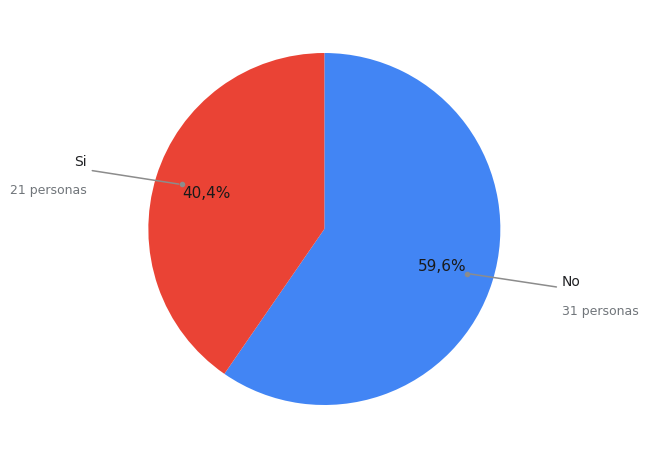

In [48]:
# 1. Asegurar nombres y valores de la tabla
# (Asumiendo que df_2_5_indicadorfi tiene como índice 'No' y 'Si')
etiquetas = df_2_5_indicadorfi.index.tolist()
valores = df_2_5_indicadorfi['fi'].values
total = sum(valores)

# Colores estilo Google (Azul y Rojo)
colores_google = ['#4285F4', '#EA4335']

# 2. Configurar la figura
fig, ax = plt.subplots(figsize=(9, 5.5), subplot_kw=dict(aspect="equal"))

# Graficar la torta con el porcentaje adentro
wedges, texts, autotexts = ax.pie(
    valores,
    autopct=lambda p: f"{p:.1f}%".replace('.', ','),
    pctdistance=0.7,
    colors=colores_google[:len(valores)],
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=1, edgecolor='none')
)

# Estilo de los porcentajes internos
for at in autotexts:
    at.set_color('#1a1a1a')
    at.set_fontsize(11)
    at.set_fontweight('medium')

# 3. Líneas guía hacia afuera con categoría y "X personas" / "X hogares" debajo
for i, p in enumerate(wedges):
    ang = (p.theta2 - p.theta1) / 2.0 + p.theta1
    y = np.sin(np.deg2rad(ang))
    x = np.cos(np.deg2rad(ang))

    # Coordenadas del punto sobre la porción
    x_punto, y_punto = 0.85 * x, 0.85 * y

    # Coordenadas hacia afuera
    horizontal_alignment = {-1: "right", 1: "left"}[int(np.sign(x))]
    x_afuera = 1.35 * np.sign(x)
    y_afuera = 1.15 * y

    # Punto gris sobre la cuña
    ax.plot(x_punto, y_punto, marker='o', markersize=3, color='#8c8c8c')

    # Texto de cantidad
    cant = int(valores[i])
    texto_personas = f"{cant} persona" if cant == 1 else f"{cant} personas"

    # Etiqueta de la categoría con la línea guía
    ax.annotate(
        f"{etiquetas[i]}\n",
        xy=(x_punto, y_punto),
        xytext=(x_afuera, y_afuera),
        horizontalalignment=horizontal_alignment,
        verticalalignment="center",
        fontsize=10,
        color="#202124",
        arrowprops=dict(arrowstyle="-", color="#8c8c8c", lw=1.1)
    )

    # Subtexto gris debajo de la etiqueta
    ax.text(
        x_afuera,
        y_afuera - 0.12,
        texto_personas,
        horizontalalignment=horizontal_alignment,
        verticalalignment="center",
        fontsize=9,
        color="#70757a"
    )

plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1)
plt.show()

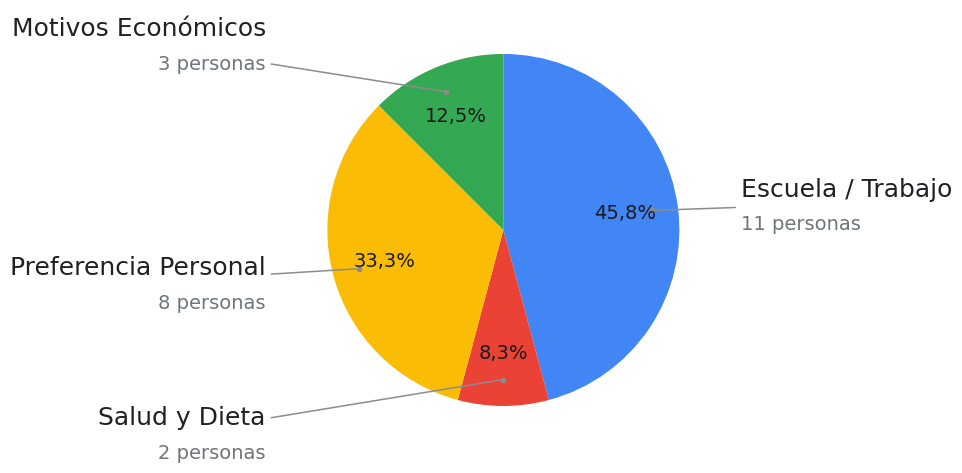

In [47]:
# 1. Etiquetas y valores
etiquetas_personalizadas = [
    'Escuela / Trabajo',
    'Salud y Dieta',
    'Preferencia Personal',
    'Motivos Económicos'
]
valores = df_2_5_estandarizado['fi'].values
total = sum(valores)

# Paleta estilo Google
colores_google = ['#4285F4', '#EA4335', '#FBBC05', '#34A853']

# 2. Configurar la figura
fig, ax = plt.subplots(figsize=(9, 5.5), subplot_kw=dict(aspect="equal"))

# Graficar la torta mostrando el porcentaje adentro
wedges, texts, autotexts = ax.pie(
    valores,
    autopct=lambda p: f"{p:.1f}%".replace('.', ','),
    pctdistance=0.7,
    colors=colores_google[:len(valores)],
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=1, edgecolor='none')
)

# Estilo de los porcentajes internos
for at in autotexts:
    at.set_color('#1a1a1a')
    at.set_fontsize(14)
    at.set_fontweight('medium')

# 3. Líneas guía hacia afuera con nombre y "X personas" debajo
for i, p in enumerate(wedges):
    ang = (p.theta2 - p.theta1) / 2.0 + p.theta1
    y = np.sin(np.deg2rad(ang))
    x = np.cos(np.deg2rad(ang))
    
    # Coordenadas del punto sobre la cuña
    x_punto, y_punto = 0.85 * x, 0.85 * y
    
    # Coordenadas externas
    horizontal_alignment = {-1: "right", 1: "left"}[int(np.sign(x))]
    x_afuera = 1.35 * np.sign(x)
    y_afuera = 1.15 * y
    
    # Punto gris sobre la cuña
    ax.plot(x_punto, y_punto, marker='o', markersize=3, color='#8c8c8c')
    
    # Texto de cantidad: "1 persona" o "X personas"
    cant = int(valores[i])
    texto_personas = f"{cant} persona" if cant == 1 else f"{cant} personas"
    
    # Nombre de la categoría con la línea guía
    ax.annotate(
        f"{etiquetas_personalizadas[i]}\n",
        xy=(x_punto, y_punto),
        xytext=(x_afuera, y_afuera),
        horizontalalignment=horizontal_alignment,
        verticalalignment="center",
        fontsize=18,
        color="#202124",
        arrowprops=dict(arrowstyle="-", color="#8c8c8c", lw=1.1)
    )
    
    # Subtexto gris justo debajo
    ax.text(
        x_afuera,
        y_afuera - 0.12,
        texto_personas,
        horizontalalignment=horizontal_alignment,
        verticalalignment="center",
        fontsize=14,
        color="#70757a"
    )

plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1)
plt.show()